# 1 · The design space and the first experiments

**The problem.** We want iron-oxide nanoparticles of **10 nm** with a **narrow size distribution** (dispersion ≤ 4 %),
made by thermal decomposition of iron oleate. Three synthesis variables are free:

| | variable | range |
|---|---|---|
| X1 | Fe-oleate concentration | 0.05 – 0.30 M |
| X2 | oleic acid : Fe ratio | 1 – 5 |
| X3 | reflux temperature | 280 – 320 °C |

Before the first synthesis we know nothing, so the first question is: **which few recipes cover the whole space best?**

> ⚠️ Throughout this tutorial the "experiments" are run on a **virtual lab** (`nanobo.virtual_lab`): an *invented*
> response surface with realistic noise. It is built to teach the method, not to describe real chemistry.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # use the local package without installing it
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nanobo as nb

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
pd.DataFrame(nb.VARIABLES, columns=["variable", "unit", "low", "high"])

,variable,unit,low,high
0,Fe-oleate concentration,M,0.05,0.3
1,Oleic acid : Fe ratio,,1.00,5.0
2,Reflux temperature,°C,280.00,320.0


## Why not a regular grid?

Six levels for each of the three variables means 6 × 6 × 6 = **216 syntheses**. Even three levels cost 27.
A **Latin hypercube** uses the same six levels of every variable with only **six** syntheses: each variable is cut into
six slices, and each slice is used by exactly one experiment.

In [3]:
U = nb.latin_hypercube(6, seed=42, unit=True)      # points in the 0-1 cube
X = nb.from_unit(U)                                  # back to real units (a simple rule of three)
plan = pd.DataFrame(X, columns=nb.SHORT).round({"conc_M": 3, "ratio_OA_Fe": 2, "temp_C": 1})
plan.index = [f"Exp {i+1}" for i in range(len(plan))]
plan

,conc_M,ratio_OA_Fe,temp_C
Exp 1,0.184,2.71,314.3
Exp 2,0.146,4.94,293.5
Exp 3,0.102,1.14,292.5
Exp 4,0.281,3.42,300.5
Exp 5,0.232,3.78,310.4
Exp 6,0.082,1.96,286.2


Check the defining property: for every variable (one row below), the six experiments fall in six *different* slices.

In [4]:
slices = pd.DataFrame(nb.slices_used(U) + 1, index=nb.SHORT, columns=plan.index)
slices   # each row is a permutation of 1..6

,Exp 1,Exp 2,Exp 3,Exp 4,Exp 5,Exp 6
conc_M,4,3,2,6,5,1
ratio_OA_Fe,3,6,1,4,5,2
temp_C,6,3,2,4,5,1


## Latin hypercube vs. random sampling

With few points, pure random sampling leaves holes and clusters. Below: 6 points, projected on two variables at a time,
and the number of *empty* slices per variable (0 is perfect).

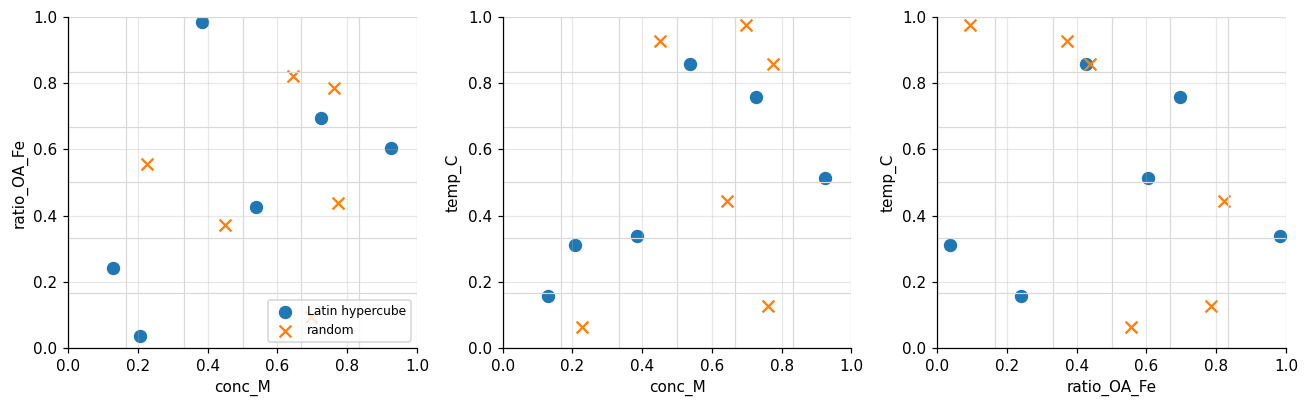

empty slices per variable  LHS: [0, 0, 0]   random: [2, 2, 3]


In [5]:
def empty_slices(U):
    n = len(U)
    return [n - len(set(row)) for row in nb.slices_used(U, n)]

U_rand = nb.random_design(6, seed=42, unit=True)
pairs = [(0, 1), (0, 2), (1, 2)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (i, j) in zip(axes, pairs):
    for k in np.linspace(0, 1, 7):
        ax.axvline(k, color="0.85", lw=0.8); ax.axhline(k, color="0.85", lw=0.8)
    ax.scatter(U[:, i], U[:, j], s=60, label="Latin hypercube")
    ax.scatter(U_rand[:, i], U_rand[:, j], s=60, marker="x", label="random")
    ax.set_xlabel(nb.SHORT[i]); ax.set_ylabel(nb.SHORT[j]); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print("empty slices per variable  LHS:", empty_slices(U), "  random:", empty_slices(U_rand))

In [6]:
# Over many seeds: how many slices does each design leave empty (6 points, 3 variables, 18 slices in total)?
lhs = [sum(empty_slices(nb.latin_hypercube(6, seed=s, unit=True))) for s in range(500)]
rnd = [sum(empty_slices(nb.random_design(6, seed=s, unit=True))) for s in range(500)]
print(f"LHS   : {np.mean(lhs):.1f} empty slices on average")
print(f"random: {np.mean(rnd):.1f} empty slices on average")

LHS   : 0.0 empty slices on average
random: 6.1 empty slices on average


## Take-aways

* The hypercube is used **once**, for the first round, when we know nothing.
* A fixed `seed` makes the plan reproducible: the same six recipes every time.
* The two measured columns (size, dispersion) are filled in after the syntheses: that is notebook 2.